## Neural Network
[Artificial neural networks (ANNs)](https://en.wikipedia.org/wiki/Artificial_neural_network), usually simply called neural networks (NNs) or neural nets, are computing systems inspired by the biological neural networks that constitute animal brains.
<p>
An ANN is based on a collection of connected units or nodes called artificial neurons, which loosely model the neurons in a biological brain. Each connection, like the synapses in a biological brain, can transmit a signal to other neurons. An artificial neuron receives signals then processes them and can signal neurons connected to it. The "signal" at a connection is a real number, and the output of each neuron is computed by some non-linear function of the sum of its inputs. The connections are called edges. Neurons and edges typically have a weight that adjusts as learning proceeds. The weight increases or decreases the strength of the signal at a connection. Neurons may have a threshold such that a signal is sent only if the aggregate signal crosses that threshold.
<p>
Typically, neurons are aggregated into layers. Different layers may perform different transformations on their inputs. Signals travel from the first layer (the input layer), to the last layer (the output layer), possibly after traversing the layers multiple times.
<p>
Met een neuraal net kun je dus ook voorspellingen maken, net als met regressie of Naive Bayes Classification of Decision Trees.
<p>
Om deze methode te kunnen toepassen, lezen we eerst weer de benodigde libraries in:




In [ ]:
! pip install pandas-datareader==0.10.0
! pip install yfinance
! pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split

from sklearn import metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from datetime import date

#Clear output
from google.colab import output
output.clear()

# Portfolio
We lezen de portfolio in:


In [ ]:
start = dt.datetime(2018,5,1)
end = dt.datetime(2024,5,1)

In [ ]:
apple = yf.download('AAPL', start, end).tz_localize(None) # Apple
shell = yf.download('SHEL', start, end).tz_localize(None) # Shell
ng = yf.download('NOC', start, end).tz_localize(None) # Northrop Grumman
tsm = yf.download('TSM', start, end).tz_localize(None) # Taiwan Semiconductor Manufacturing Company (TSMC)
rio = yf.download('RIO', start, end).tz_localize(None) # Rio Tinto Group
ge = yf.download('GE', start, end).tz_localize(None) # General Electric Company
gs = yf.download('GS', start, end).tz_localize(None) # The Goldman Sachs Group
bond = yf.download('BOND', start, end).tz_localize(None) # PIMCO Active Bond Exchange-Traded Fund
btc = yf.download('BTC-USD', start, end).tz_localize(None) # Bitcoin USD
xrp = yf.download('XRP-USD', start, end).tz_localize(None) # XRP USD

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Portfolio-tabel van tabelnamen voorzien, alleen de slotkoersen selecteren en schonen:

In [ ]:
portfolio = pd.concat([apple.add_suffix("_Apple"), shell.add_suffix("_Shell"), ng.add_suffix("_Northrop"),tsm.add_suffix("_TSMC"), rio.add_suffix("_RioTinto"), ge.add_suffix("_GE"), gs.add_suffix("_GoldmanSachs"), bond.add_suffix("_Bond"), btc.add_suffix("_Bitcoin"), xrp.add_suffix("_Ripple")], axis=1)
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]]
nans_gevuld = portfolio_gefilterd.ffill()
nans_gevuld

Price,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Ticker,AAPL_Apple,SHEL_Shell,NOC_Northrop,TSM_TSMC,RIO_RioTinto,GE_GE,GS_GoldmanSachs,BOND_Bond,BTC-USD_Bitcoin,XRP-USD_Ripple
Date,,,,,,,,,,
2018-05-01,42.275002,69.050003,307.220001,38.930000,54.560001,67.333748,236.669998,102.639999,9119.009766,0.841407
2018-05-02,44.142502,69.180000,307.160004,37.750000,55.020000,67.956764,234.050003,102.589996,9235.919922,0.859094
2018-05-03,44.222500,69.610001,315.679993,38.099998,55.459999,66.758652,233.410004,102.580002,9743.860352,0.884466
2018-05-04,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9700.759766,0.895442
2018-05-05,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9858.150391,0.905103
...,...,...,...,...,...,...,...,...,...,...
2024-04-26,169.300003,73.269997,480.450012,138.300003,68.239998,162.350006,427.570007,89.120003,63755.320312,0.526112
2024-04-27,169.300003,73.269997,480.450012,138.300003,68.239998,162.350006,427.570007,89.120003,63419.140625,0.517775


In [ ]:
nans_gevuld.columns = ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]

In [ ]:
nans_gevuld.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Close_Apple,2192.0,117.863469,50.651056,35.547501,60.502501,131.460007,162.509995,198.110001
Close_Shell,2192.0,53.153107,12.100053,21.620001,41.959999,57.169998,62.849998,73.639999
Close_Northrop,2192.0,378.636314,74.608505,226.229996,313.950012,363.679993,453.420013,549.010010
Close_TSMC,2192.0,80.870265,31.465719,34.360001,48.645000,85.639999,106.414999,149.199997
Close_RioTinto,2192.0,63.562897,10.852438,36.419998,55.675000,62.090000,70.252499,94.650002
Close_GE,2192.0,61.039237,22.948507,27.362900,46.539359,57.566757,66.588043,164.490005
Close_GoldmanSachs,2192.0,287.198518,75.883182,134.970001,211.187496,304.250000,349.269989,430.809998
Close_Bond,2192.0,102.394457,8.304809,85.360001,92.944998,104.080002,109.762501,113.180000
Close_Bitcoin,2192.0,24330.341700,17764.096479,3236.761719,8678.960938,20270.327148,37608.831055,73083.500000
Close_Ripple,2192.0,0.493666,0.266014,0.139635,0.304512,0.437716,0.608798,1.839236


# Grondstoffen en macro-economische indicatoren

In [ ]:
inflatie = web.get_data_fred('T10YIE', start, end) #inflatie
rente = web.get_data_fred('FEDFUNDS', start, end) #rente

graan = web.get_data_fred('PWHEAMTUSDM', start, end) #graan
hout = web.get_data_fred('WPU08', start, end) #hout
katoen = web.get_data_fred('PCOTTINDUSDM', start, end) #katoen
koffie = web.get_data_fred('WPU026301', start, end) #koffiebonen
rubber = web.get_data_fred('PRUBBUSDM', start, end) #rubber
vlees = web.get_data_fred('PBEEFUSDM', start, end) #vleesprijs
wol = web.get_data_fred('PWOOLFUSDM', start, end) #wol
zonnebloem = web.get_data_fred('PSUNOUSDM', start, end) #zonnebloemolie

gas = web.get_data_fred('GASREGW', start, end) #gas (US Regular All Formulations Gas Price)
kolen = web.get_data_fred('WPU058103', start, end) #kolen (Producer Price Index by Commodity: Fuels and Related Products and Power: Other Petroleum and Coal Products, Including Coke Oven Products, Not Elsewhere Classified)
oil = yf.download('CL=F', start, end).tz_localize(None) #olie
uranium = web.get_data_fred('PURANUSDM', start, end) #uranium

goud = yf.download('GC=F', start, end).tz_localize(None) #goud future
koper = web.get_data_fred('PCOPPUSDM', start, end) #koperprijs
palladium = yf.download('PA=F', start, end).tz_localize(None) #palladium
staal = web.get_data_fred('WPU101707', start, end) #staal (Producer Price Index by Commodity: Metals and Metal Products: Cold Rolled Steel Sheet and Strip )
zilver = yf.download('SI=F', start, end).tz_localize(None) #zilver future

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [ ]:
indicatoren = pd.concat([rente, inflatie], axis=1)
indicatoren.columns = ["Rente", "Inflatie"]

grondstoffen_1 = pd.concat([graan, koffie, vlees, gas, kolen, hout, katoen, rubber, wol, zonnebloem, uranium], axis=1)
grondstoffen_1.columns = ["Close_Graan", "Close_Koffie", "Close_Vlees", "Close_Gas", "Close_Kolen", "Close_Hout", "Close_Katoen", "Close_Rubber", "Close_Wol", "Close_Zonnebloem", "Close_Uranium"]

grondstoffen_2 = pd.concat([oil.add_suffix("_Olie"), goud.add_suffix("_Goud"), palladium.add_suffix("_Palladium")], axis = 1)
grondstoffen_2 = grondstoffen_2.loc[:, ["Close_Olie", "Close_Goud", "Close_Palladium"]]
grondstoffen_2.columns = ["Close_Olie", "Close_Goud", "Close_Palladium"]

In [ ]:
indicatoren = indicatoren.ffill()
grondstoffen_1 = grondstoffen_1.ffill()
grondstoffen_2 = grondstoffen_2.ffill()

In [ ]:
grondstoffen_compleet = pd.concat([grondstoffen_1, grondstoffen_2], axis=1)
grondstoffen_compleet = grondstoffen_compleet.ffill()
grondstoffen_compleet

,Close_Graan,Close_Koffie,Close_Vlees,Close_Gas,Close_Kolen,Close_Hout,Close_Katoen,Close_Rubber,Close_Wol,Close_Zonnebloem,Close_Uranium,Close_Olie,Close_Goud,Close_Palladium
2018-05-01,192.703830,194.200,188.000000,NaN,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,67.250000,1303.800049,938.450012
2018-05-02,192.703830,194.200,188.000000,NaN,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,67.930000,1302.599976,962.349976
2018-05-03,192.703830,194.200,188.000000,NaN,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,68.430000,1310.699951,960.900024
2018-05-04,192.703830,194.200,188.000000,NaN,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,69.720001,1312.699951,959.450012
2018-05-07,192.703830,194.200,188.000000,2.845,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,70.730003,1312.199951,964.299988
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-25,208.381685,253.486,270.568182,3.668,638.273,298.811,90.602273,107.788108,925.980943,1171.085417,71.638853,83.570000,2329.800049,981.099976
2024-04-26,208.381685,253.486,270.568182,3.668,638.273,298.811,90.602273,107.788108,925.980943,1171.085417,71.638853,83.849998,2334.800049,957.400024
2024-04-29,208.381685,253.486,270.568182,3.653,638.273,298.811,90.602273,107.788108,925.980943,1171.085417,71.638853,82.629997,2345.399902,976.700012
2024-04-30,208.381685,253.486,270.568182,3.653,638.273,298.811,90.602273,107.788108,925.980943,1171.085417,71.638853,81.930000,2291.399902,951.900024


# Alles compleet

In [ ]:
apt = pd.concat([nans_gevuld, grondstoffen_compleet, indicatoren], axis=1)
apt_fill = apt.ffill()
apt_fill = apt_fill.dropna()
apt_fill

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,...,Close_Katoen,Close_Rubber,Close_Wol,Close_Zonnebloem,Close_Uranium,Close_Olie,Close_Goud,Close_Palladium,Rente,Inflatie
2018-05-07,46.290001,69.730003,317.130005,38.450001,55.480000,67.429596,237.199997,102.720001,9373.009766,0.832641,...,94.478571,76.123690,1648.876010,938.999457,21.978261,70.730003,1312.199951,964.299988,1.70,2.17
2018-05-08,46.512501,70.029999,329.269989,39.180000,55.410000,68.388084,237.000000,102.589996,9234.820312,0.813970,...,94.478571,76.123690,1648.876010,938.999457,21.978261,69.059998,1312.000000,965.599976,1.70,2.16
2018-05-09,46.840000,71.709999,327.589996,39.349998,56.560001,70.065437,241.729996,102.440002,9325.179688,0.802043,...,94.478571,76.123690,1648.876010,938.999457,21.978261,71.139999,1311.300049,972.799988,1.70,2.18
2018-05-10,47.509998,71.029999,326.410004,39.770000,57.349998,70.400902,243.440002,102.559998,9043.940430,0.758237,...,94.478571,76.123690,1648.876010,938.999457,21.978261,71.360001,1320.800049,996.099976,1.70,2.17
2018-05-11,47.147499,71.989998,325.299988,39.910000,57.389999,69.969589,242.919998,102.690002,8441.490234,0.684948,...,94.478571,76.123690,1648.876010,938.999457,21.978261,70.699997,1319.000000,987.400024,1.70,2.15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-27,169.300003,73.269997,480.450012,138.300003,68.239998,162.350006,427.570007,89.120003,63419.140625,0.517775,...,90.602273,107.788108,925.980943,1171.085417,71.638853,83.849998,2334.800049,957.400024,5.33,2.43
2024-04-28,169.300003,73.269997,480.450012,138.300003,68.239998,162.350006,427.570007,89.120003,63113.230469,0.510377,...,90.602273,107.788108,925.980943,1171.085417,71.638853,83.849998,2334.800049,957.400024,5.33,2.43
2024-04-29,173.500000,73.120003,486.220001,138.500000,69.010002,164.490005,430.809998,89.470001,63841.121094,0.515432,...,90.602273,107.788108,925.980943,1171.085417,71.638853,82.629997,2345.399902,976.700012,5.33,2.41
2024-04-30,170.330002,71.660004,485.029999,137.339996,67.830002,161.820007,426.709991,89.180000,60636.855469,0.500065,...,90.602273,107.788108,925.980943,1171.085417,71.638853,81.930000,2291.399902,951.900024,5.33,2.41


# Neuraal netwerk voor regressie
Laten we eens kijken of we een voorspelling kunnen maken. In dit voorbeeld gaan we kijken of we de koers van Goldman Sachs kunnen voorspellen op basis van de rente, obligatie en goud.
<p>
Dat doen we door eerst de data te verdelen in een trainings-set (40%) en een test-set (60%). Met de trainings-set 'train' je het model = laat je het model berekenen welke koers van het aandeel GS bij welke prijzen/koersen van de rente, obligatie en olie horen.
<p>
Met de test-set voorspel je vervolgens welke koers van GS bij welke prijzen/koersen van de rente, obligatie en olie horen.  

In [ ]:
X = apt_fill[['Rente', 'Close_Bond', 'Close_Olie']]
y = apt_fill['Close_GoldmanSachs']


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.6)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

Vervolgens trainen we het model:

In [ ]:
model = MLPRegressor(hidden_layer_sizes = (64, 64, 64),
                     activation = "relu",
                     random_state = 42, max_iter = 2000)

model.fit(X_train, y_train)
y_pred = model.predict(X_val)

Is dit neurale netwerk nu een goede voorspeller?

In [ ]:
mae = metrics.mean_absolute_error(y_val, y_pred)
mse = metrics.mean_squared_error(y_val, y_pred)
rmse = mse**0.5
r2 = metrics.r2_score(y_val, y_pred)


print(f"""
Mean Absolute Error: \t{mae:.2f}
Root Mean Square Error: \t{rmse:.2f}
r2: \t{r2:.2f}
""")


Mean Absolute Error: 	13.49
Root Mean Square Error: 	17.80
r2: 	0.95



Je zit er dus met dit voorspelmodel gemiddeld tussen de 13,49 en 17,80 dollar naast.<br>
De r-kwadraat is hoog: 0,95 - dit suggereert een sterk verband tussen de X'n (rente, obligatie en olie) en de Y (koers van GS).

In [ ]:
df = pd.DataFrame()

df['Koers_GS'] = y_val
df['Voorspelde_koers_GS'] = y_pred


weight = df[['Koers_GS', 'Voorspelde_koers_GS']].pct_change(axis = 'columns', periods = 1 ).abs()
total = sum(weight['Voorspelde_koers_GS'])

average_miscalc = (total / len(weight)) * 100
print(f"De afwijking tussen de koers en de voorspelde koers is gemiddeld {round(average_miscalc, 2)} % \n\n\n" )

De afwijking tussen de koers en de voorspelde koers is gemiddeld 4.57 % 





We kunnnen een neuraal netwerk dus gebruiken bij het voorspellen van een continue variabele.

## Scatterplot
In onderstaand scatterplot wordt de voorspelde koers en de werkelijke koers tegen elkaar uitgezet:

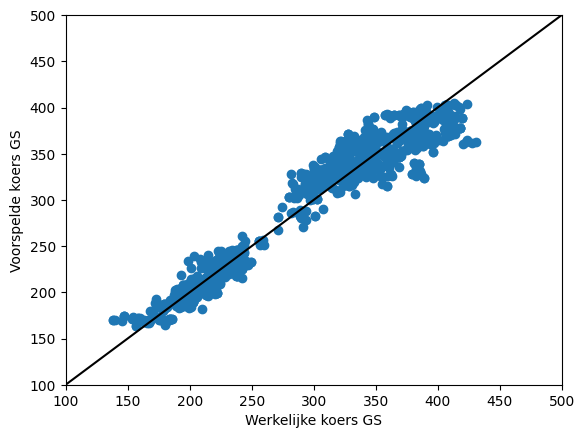

In [ ]:
plt.scatter(y_val, y_pred)
plt.xlim(100, 500)
plt.ylim(100, 500)
plt.ylabel('Voorspelde koers GS')
plt.xlabel('Werkelijke koers GS')
plt.plot([0, 500], [0,500], 'black') #1 to 1 line
plt.show()

Het model van het neural network heeft predictions gemaakt en deze staan uitgezet tegen de daadwerkelijke koers van Goldman Sachs. In het ideale geval liggen alle punten op de ideaallijn en hoe dichter deze bij de lijn liggen, hoe beter de voorspellingen zijn. Hieruit blijkt dat het neural network een redelijk goed model is voor het bepalen van een continue variabele.

#Nadeel van een neuraal netwerk
Probeer de uitkomst van bovenstaande regressie-analyse met behulp van een neuraal netwerk maar eens uit te leggen aan een leek:<br>
- Hoe ziet het voorspelmodel er nu uit?<br>
- Wat gebeurt er precies in / tussen de 3 hidden layers met 64 neuronen?<br>

<p>

Bij de andere voorspelmodellen (lineaire regressie, naive Bayes en beslisbomen) is nog enigszins te volgen wat het model doet. Het neurale netwerk is een fijn voorbeeld van een black box:<br>
alleen wat er in gaat (data) en wat er uitkomt (voorspelling) is bekend.<br>
<p>
https://en.wikipedia.org/wiki/Black_box

